# 00 — Data Quality, Integrity & Research Readiness
**Dubai Residential Market Intelligence V2 | Frozen raw transaction snapshot**

**Purpose:** determine which source records and analytical cohorts are suitable for each of the 15 planned research questions. This notebook **does not** estimate house-price growth or investment opportunities. The raw Parquet is immutable; every diagnostic is computed dynamically and exported only after the quality gate.

**Research period:** complete calendar years 2010–2025; 2026 is provisional and isolated. **Grain:** one DLD registered transaction, *not* one dwelling. **Outputs:** documented tables, coverage diagnostics, figures and a calculated research readiness gate.

## 01 · Decision policy and evidence boundaries
**BLOCK** if the frozen snapshot cannot be verified, critical source validation fails, IDs are duplicated, source fields change, cohort arithmetic fails, or exports cannot be verified. **CONDITIONAL** means data inputs exist but selection, coverage, small-sample or metadata restrictions apply. **PASS** is limited to input availability and never certifies causality, forecasting accuracy or an adjusted estimator.

Eligibility is not data quality: market activity, residential pricing, matched segments and amenity analysis have different denominators. No source values are altered, nulls imputed or outliers deleted. Decisions below are computed, not assigned by research-question number.

In [1]:
# 03 — Environment and portable project path (run from project root or notebooks/)
import sys, json, platform, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt
from IPython.display import display, Markdown

candidates = [Path.cwd(), Path.cwd().parent]
ROOT = next((p for p in candidates if (p/'src'/'loader.py').is_file() and (p/'docs'/'research_plan.md').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open V2 project root or its notebooks/ folder; src/loader.py and docs/research_plan.md are required.')
sys.path.insert(0, str(ROOT)) if str(ROOT) not in sys.path else None
from src.loader import load_and_validate
from src.validation import QUALITY_BITS, SQFT_PER_SQM, REQUIRED_COLUMNS
from src.cleaning import clean_transactions, cohort_audit, COHORT_COLUMNS
from src.features import engineer_features
import importlib.metadata as metadata
VERSIONS = {p:metadata.version(p) for p in ['pandas','numpy','matplotlib','pyarrow','pytest']}
print('Project:',ROOT,'| Python:',platform.python_version(),'| Packages:',VERSIONS)
print('Notebook policy: read-only source, 2010–2025 primary, 2026 provisional.')

Project: e:\DataAnalytics\Projects\Dubai_Real_Estate_Analytics_V2 | Python: 3.11.18 | Packages: {'pandas': '2.3.3', 'numpy': '2.4.6', 'matplotlib': '3.11.2', 'pyarrow': '26.0.1', 'pytest': '9.2.0'}
Notebook policy: read-only source, 2010–2025 primary, 2026 provisional.


In [2]:
# 04 — Load and pin the immutable raw snapshot
EXPECTED_SHA = '8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b39384561777afb8425417e'
raw, source, report = load_and_validate(expected_sha256=EXPECTED_SHA, strict=True)
manifest = pd.DataFrame([{'source_sha256':source.sha256,'path':source.path,'bytes':source.size_bytes,
                          'raw_rows':source.row_count,'raw_columns':source.column_count,
                          'parquet_row_groups':source.parquet_row_groups,'python_version':platform.python_version(),
                          'pandas_version':VERSIONS['pandas'],'pyarrow_version':VERSIONS['pyarrow']}])
assert source.row_count == len(raw) and source.column_count == len(raw.columns)
display(manifest)

,source_sha256,path,bytes,raw_rows,raw_columns,parquet_row_groups,python_version,pandas_version,pyarrow_version
0,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,E:\DataAnalytics\Projects\Dubai_Real_Estate_An...,22819023,1382848,20,12,3.11.18,2.3.3,26.0.1


In [3]:
# 05 — Source validation: structural errors block; anomalies remain documented
assert report.passed and not report.errors, report.summary()
validation_findings = pd.DataFrame([{'code':f.code,'severity':f.severity,'affected_rows':f.count,'message':f.message} for f in report.findings],
                                   columns=['code','severity','affected_rows','message'])
display(validation_findings)
print('Structural PASS:',report.passed,'| Warning categories:',len(report.warnings))

,code,severity,affected_rows,message
0,price_psf_nonpositive,warning,24,price_psf is zero or negative: invalid as a po...
1,publisher_quality_flags_nonzero,warning,28693,Publisher-marked records are retained in raw l...
2,building_name_missing_2026,warning,113943,building_name is missing in 2026 transactions;...
3,has_parking_missing_2026,warning,43942,has_parking is missing in 2026 transactions; t...
4,procedure_name_en_missing_2026,warning,26971,procedure_name_en is missing in 2026 transacti...
5,procedure_completeness,warning,26971,Missing procedure/pre-registration metadata; d...


Structural PASS: True | Warning categories: 6


In [4]:
# 06 — Physical columns and analytical semantics, no coercion
schema_profile = pd.DataFrame(report.column_profile)
assert set(REQUIRED_COLUMNS).issubset(raw.columns) and len(schema_profile)==len(raw.columns)
display(schema_profile.sort_values('missing_pct',ascending=False))
print('Date storage:',raw['instance_date'].dtype,'| Area ID:',raw['area_id'].dtype,'| Nullable parking:',raw['has_parking'].dtype)

,column,dtype,rows,missing_n,missing_pct,non_null_unique
7,building_name,object,1382848,408903,29.56963,4701
5,project_name,object,1382848,284699,20.58787,3427
11,rooms_bucket,float64,1382848,281078,20.32602,6
6,master_project_name,object,1382848,253337,18.31995,185
9,property_sub_type,object,1382848,198042,14.32131,35
12,has_parking,object,1382848,43942,3.17764,2
18,is_pre_registration,object,1382848,26971,1.95040,2
17,procedure_name_en,object,1382848,26971,1.95040,18
16,procedure_id,float64,1382848,26971,1.95040,18
15,price_psf,float64,1382848,186,0.01345,301822


Date storage: object | Area ID: float64 | Nullable parking: object


In [5]:
# 07 — Transaction ID grain; same attributes do not mean same property
id_missing = int(raw['transaction_id'].isna().sum())
id_duplicates = int(raw['transaction_id'].duplicated(keep=False).sum())
assert id_missing == 0 and id_duplicates == 0
business_cols=['instance_date','area_id','building_name','property_type_label','rooms_bucket','area_sqm','price_aed']
matching_fingerprints=int(raw.duplicated(subset=business_cols,keep=False).sum())
transaction_grain = pd.DataFrame([{'rows':len(raw),'unique_transaction_ids':raw['transaction_id'].nunique(),
                                   'null_ids':id_missing,'repeated_ids':id_duplicates,
                                   'matching_business_fingerprint_rows_not_deduplicated':matching_fingerprints}])
# Cross-tab only to characterize repeated fingerprints; never deduplicate based on it.
fingerprint_repeated=raw.duplicated(subset=business_cols,keep=False)
fingerprint_summary=(pd.DataFrame({'year':pd.to_datetime(raw.instance_date,errors='coerce').dt.year,
 'property_type':raw.property_type_label,'registration':raw.reg_type_label,
 'repeated_fingerprint':fingerprint_repeated})
 .groupby(['year','property_type','registration'],dropna=False,observed=True)
 .repeated_fingerprint.agg(['size','sum']).reset_index())
fingerprint_summary['repeated_pct']=100*fingerprint_summary['sum']/fingerprint_summary['size']
display(transaction_grain,fingerprint_summary.sort_values('sum',ascending=False).head(15))

,rows,unique_transaction_ids,null_ids,repeated_ids,matching_business_fingerprint_rows_not_deduplicated
0,1382848,1382848,0,0,124595


,year,property_type,registration,size,sum,repeated_pct
50,2009,Unit,Off-Plan,32000,10738,33.556250
51,2009,Unit,Ready,25613,7286,28.446492
146,2025,Unit,Off-Plan,125090,6600,5.276201
140,2024,Unit,Off-Plan,96000,5727,5.965625
153,2026,Unit,Off-Plan,83784,5473,6.532273
75,2013,Unit,Ready,40445,4375,10.817159
46,2008,Unit,Ready,12942,3895,30.095812
134,2023,Unit,Off-Plan,59156,3881,6.560619
145,2025,Land,Ready,21527,3376,15.682631
63,2011,Unit,Ready,21108,3152,14.932727


In [6]:
# 08 — Source category domains and cross-classification; retain all registered property types
category_counts=pd.concat([raw[x].astype('string').fillna('<NULL>').value_counts(dropna=False).rename_axis('value').reset_index(name='n').assign(column=x)
                           for x in ['reg_type_label','property_type_label','usage_label']],ignore_index=True)
category_cross = pd.crosstab(raw['property_type_label'],raw['usage_label'],dropna=False)
registration_cross = pd.crosstab(raw['reg_type_label'],raw['is_pre_registration'].astype('string').fillna('<NULL>'),dropna=False)
display(category_counts, category_cross, registration_cross)
assert category_cross.to_numpy().sum()==len(raw)

,value,n,column
0,Ready,736939,reg_type_label
1,Off-Plan,645909,reg_type_label
2,Unit,1066079,property_type_label
3,Villa,179189,property_type_label
4,Land,113807,property_type_label
5,Building,23773,property_type_label
6,Residential,1190250,usage_label
7,Commercial,132317,usage_label
8,Other,60281,usage_label


usage_label,Commercial,Other,Residential
property_type_label,,,
Building,9775,1698,12300
Land,28858,20177,64772
Unit,67553,36553,961973
Villa,26131,1853,151205


is_pre_registration,<NULL>,False,True
reg_type_label,,,
Off-Plan,0,0,645909
Ready,26971,709968,0


In [7]:
# 09 — Reuse validated modules; verify original values and row/index preservation
cleaned = clean_transactions(raw, strict=True)
featured = engineer_features(cleaned)
assert len(raw)==len(cleaned)==len(featured)
assert raw.index.equals(cleaned.index) and raw.index.equals(featured.index)
assert list(raw.columns) == list(cleaned.columns[:len(raw.columns)])
assert list(raw.columns) == list(featured.columns[:len(raw.columns)])
changed=[col for col in raw.columns if not raw[col].equals(cleaned[col]) or not raw[col].equals(featured[col])]
assert not changed, f'Source fields changed: {changed}'
assert featured['transaction_id'].equals(raw['transaction_id'])
print('PASS: 100% row/index/source-column value preservation; new columns:',len(featured.columns)-len(raw.columns))

PASS: 100% row/index/source-column value preservation; new columns: 18


### Source semantic boundary
`transaction_id` identifies registered transactions, **not** stable individual dwellings. The data lacks rental income, income, current listings, identical-unit repeat-sales links, and confirmed arm's-length status. `Ready` is a registration category and must **not** be relabeled "verified resale". Price-per-sqm is not an independent property valuation.

## 03 · Population hierarchy
P0 is eligibility for registered activity (not a restatement of raw rows). P1 Core is built-residential with valid price and area; P1 Strict additionally requires zero publisher quality flags; P2 requires known comparability fields; P3 requires historical known bedroom **and** parking; P4 is a **parallel** 2026 activity slice. Never add overlapping cohort counts.

,cohort_id,parent,input_n,retained_n,excluded_n
0,P0_ALL_SALES,raw source,1382848,1382848,0
1,P1_RESIDENTIAL_CORE,P0_ALL_SALES,1382848,1113177,269671
2,P1_STRICT,P1_RESIDENTIAL_CORE,1113177,1094417,18760
3,P2_KNOWN_SEGMENT,P1_STRICT,1094417,1041009,53408
4,P3_AMENITY_KNOWN,P1_STRICT,1094417,712512,381905
5,P4_2026_PROVISIONAL,P0_ALL_SALES,1382848,136035,1246813


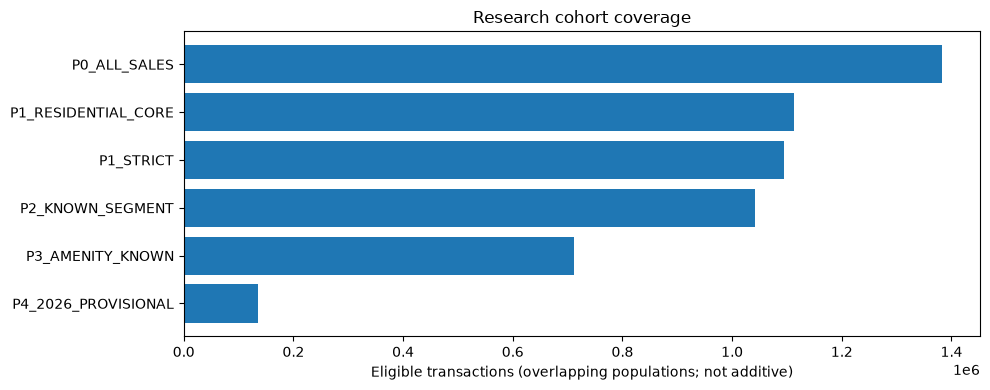

In [8]:
# 12 — Parent-aware cohort reconciliation
cohorts=cohort_audit(cleaned)
assert (cohorts['input_n']==cohorts['retained_n']+cohorts['excluded_n']).all()
assert cohorts.iloc[0].input_n==len(raw)
flags=cleaned[list(COHORT_COLUMNS)]
assert (flags['eligible_residential_strict'] & ~flags['eligible_residential_core']).sum()==0
assert (flags['eligible_known_segment'] & ~flags['eligible_residential_strict']).sum()==0
assert (flags['eligible_amenity_known'] & ~flags['eligible_residential_strict']).sum()==0
display(cohorts)
fig,ax=plt.subplots(figsize=(10,4)); ax.barh(cohorts['cohort_id'],cohorts['retained_n']);ax.invert_yaxis()
ax.set_xlabel('Eligible transactions (overlapping populations; not additive)');ax.set_title('Research cohort coverage');plt.tight_layout();
figpath=ROOT/'reports'/'figures';figpath.mkdir(parents=True,exist_ok=True);fig.savefig(figpath/'00_cohort_coverage.png',dpi=150,bbox_inches='tight');plt.show()

In [9]:
# 13 — Reconcile the legacy simplistic residential selection with V2 Core
simple=raw['property_type_label'].isin(['Unit','Villa']) & raw['usage_label'].eq('Residential')
core=cleaned['eligible_residential_core']
legacy_delta=raw.loc[simple & ~core,['transaction_id','instance_date','price_aed','area_sqm','quality_flags','reg_type_label']].copy()
reverse_delta=raw.loc[core & ~simple,['transaction_id']].copy()
assert reverse_delta.empty, 'V2 Core unexpectedly includes non-built-residential records'
legacy_reconciliation=pd.DataFrame([{'simple_type_usage_n':int(simple.sum()),'v2_residential_core_n':int(core.sum()),
                                    'simple_only_n':len(legacy_delta),'v2_only_n':len(reverse_delta)}])
display(legacy_reconciliation, legacy_delta.head(10))
print('The difference is observed, never inferred from a guessed exclusion reason.')

,simple_type_usage_n,v2_residential_core_n,simple_only_n,v2_only_n
0,1113178,1113177,1,0


,transaction_id,instance_date,price_aed,area_sqm,quality_flags,reg_type_label
1373592,1-11-2026-30754,2026-10-07,3241666,NaN,2,Ready


The difference is observed, never inferred from a guessed exclusion reason.


,from,to,start_n,retained_n,incrementally_excluded_n
0,raw_source,P0_market_activity,1382848,1382848,0
1,P0_market_activity,P1_built_residential,1382848,1113178,269670
2,P1_built_residential,P1_residential_core,1113178,1113177,1
3,P1_residential_core,P1_strict,1113177,1094417,18760


,reason,overlapping_raw_n,among_simple_residential_n,among_P1_strict_n
0,not_built_residential,269670,0,0
1,not_P0_activity_eligible,0,0,0
2,nonpositive_or_nonfinite_price,0,0,0
3,nonpositive_or_nonfinite_area,2,1,0
4,publisher_quality_flag_nonzero,28693,18761,0
5,missing_area_id,148,35,32
6,unknown_bedroom,281078,54935,53376
7,unknown_parking,43942,26868,26342


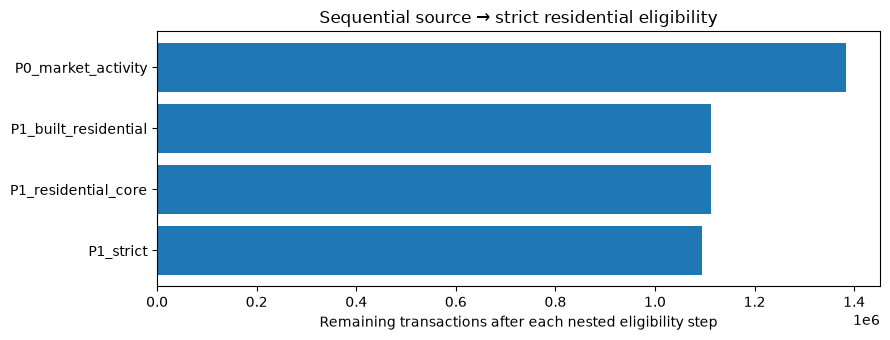

In [10]:
# 14 — Explicit sequential funnel AND overlapping diagnostic causes
price = pd.to_numeric(raw['price_aed'], errors='coerce')
area = pd.to_numeric(raw['area_sqm'], errors='coerce')
finite_price = pd.Series(np.isfinite(price.to_numpy(dtype=float, na_value=np.nan)), index=raw.index)
finite_area = pd.Series(np.isfinite(area.to_numpy(dtype=float, na_value=np.nan)), index=raw.index)
reason_masks = {
 'not_built_residential': ~simple,
 'not_P0_activity_eligible': ~cleaned['eligible_market_activity'],
 'nonpositive_or_nonfinite_price': ~(finite_price & price.gt(0)),
 'nonpositive_or_nonfinite_area': ~(finite_area & area.gt(0)),
 'publisher_quality_flag_nonzero': raw['quality_flags'].ne(0),
 'missing_area_id': raw['area_id'].isna(),
 'unknown_bedroom': ~pd.to_numeric(raw['rooms_bucket'],errors='coerce').isin([0,1,2,3,4,5]),
 'unknown_parking': ~raw['has_parking'].map(lambda v:isinstance(v,(bool,np.bool_)))
}
exclusion_reasons = pd.DataFrame([{'reason':key,'overlapping_raw_n':int(mask.sum()),
  'among_simple_residential_n':int((mask & simple).sum()),
  'among_P1_strict_n':int((mask & cleaned['eligible_residential_strict']).sum())}
 for key,mask in reason_masks.items()])
# Sequential steps follow existing *module-defined* eligibility, not a new cleaner.
stages = [('raw_source',pd.Series(True,index=raw.index)),
          ('P0_market_activity',cleaned['eligible_market_activity']),
          ('P1_built_residential',cleaned['eligible_market_activity'] & simple),
          ('P1_residential_core',cleaned['eligible_residential_core']),
          ('P1_strict',cleaned['eligible_residential_strict'])]
funnel=[]
for (name,mask),(next_name,next_mask) in zip(stages,stages[1:]):
 assert not (next_mask & ~mask).any(), (name,next_name,'not nested')
 funnel.append({'from':name,'to':next_name,'start_n':int(mask.sum()),
                'retained_n':int(next_mask.sum()),'incrementally_excluded_n':int((mask & ~next_mask).sum())})
sequential_funnel=pd.DataFrame(funnel)
assert int(sequential_funnel.incrementally_excluded_n.sum()) == len(raw)-int(cleaned.eligible_residential_strict.sum())
assert int((simple & ~cleaned.eligible_residential_core).sum())==len(legacy_delta)
display(sequential_funnel,exclusion_reasons)
fig,ax=plt.subplots(figsize=(9,3.5))
ax.barh(sequential_funnel['to'],sequential_funnel['retained_n'])
ax.invert_yaxis();ax.set_xlabel('Remaining transactions after each nested eligibility step')
ax.set_title('Sequential source → strict residential eligibility')
plt.tight_layout();fig.savefig(figpath/'00_cohort_waterfall.png',dpi=150,bbox_inches='tight');plt.show()

cohort,eligible_amenity_known,eligible_known_segment,eligible_market_activity,eligible_residential_core,eligible_residential_strict
year,,,,,
2021,94.466762,94.466762,100.0,78.993336,98.638717
2022,96.582442,96.582442,100.0,78.241560,98.282417
2023,97.708242,97.708242,100.0,82.394671,98.200687
2024,98.380734,98.380734,100.0,86.524056,98.300674
2025,98.909824,98.909824,100.0,84.912687,98.117821
2026,0.000000,96.276732,100.0,84.939170,97.974850


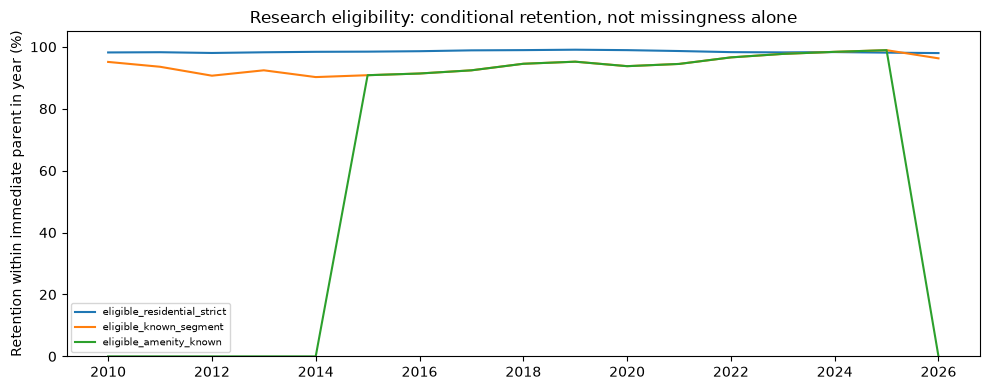

In [11]:
# 15 — Explicit denominators: raw-year share and parent/cohort conditional retention
analysis_year=featured['year']
cohort_coverage_rows=[]
cohort_parents={'eligible_market_activity':None,
 'eligible_residential_core':'eligible_market_activity',
 'eligible_residential_strict':'eligible_residential_core',
 'eligible_known_segment':'eligible_residential_strict',
 'eligible_amenity_known':'eligible_residential_strict'}
for y in sorted(int(v) for v in analysis_year.dropna().unique()):
 yr=analysis_year.eq(y).fillna(False); raw_n=int(yr.sum())
 for name,parent in cohort_parents.items():
  n=int((yr & cleaned[name]).sum()); parent_n=int((yr & cleaned[parent]).sum()) if parent else raw_n
  cohort_coverage_rows.append({'year':y,'cohort':name,'raw_year_n':raw_n,
    'parent_year_n':parent_n,'eligible_n':n,
    'share_of_raw_year_pct':100*n/raw_n if raw_n else np.nan,
    'retention_of_parent_pct':100*n/parent_n if parent_n else np.nan})
cohort_coverage=pd.DataFrame(cohort_coverage_rows)
assert (cohort_coverage.eligible_n<=cohort_coverage.parent_year_n).all()
display(cohort_coverage.query('year >= 2021').pivot(index='year',columns='cohort',values='retention_of_parent_pct'))
fig,ax=plt.subplots(figsize=(10,4))
for name in ['eligible_residential_strict','eligible_known_segment','eligible_amenity_known']:
 sub=cohort_coverage.query('cohort == @name and year >= 2010')
 ax.plot(sub.year,sub.retention_of_parent_pct,label=name)
ax.set_ylabel('Retention within immediate parent in year (%)');ax.set_ylim(0,105)
ax.set_title('Research eligibility: conditional retention, not missingness alone');ax.legend(fontsize=7)
plt.tight_layout();figpath=ROOT/'reports'/'figures';figpath.mkdir(parents=True,exist_ok=True)
fig.savefig(figpath/'00_retention_by_year.png',dpi=150,bbox_inches='tight');plt.show()

,year,core_n,core_median_psm,strict_n,strict_median_psm,median_difference_pct
0,2010,28231,9282.399143,27717,9282.399143,0.000000
1,2011,22335,8650.519031,21945,8650.893986,0.004334
2,2012,26643,9187.154452,26113,9179.313715,-0.085345
3,2013,48253,9847.402491,47400,9857.946524,0.107074
4,2014,42002,10895.330509,41323,10903.638151,0.076250
5,2015,32082,10511.625862,31581,10538.810519,0.258615
6,2016,31205,10666.666667,30762,10684.534589,0.167512
7,2017,35675,10830.965909,35267,10874.857978,0.405246
8,2018,25082,11140.303570,24814,11193.686019,0.479183
9,2019,30950,10443.432995,30661,10461.872288,0.176564


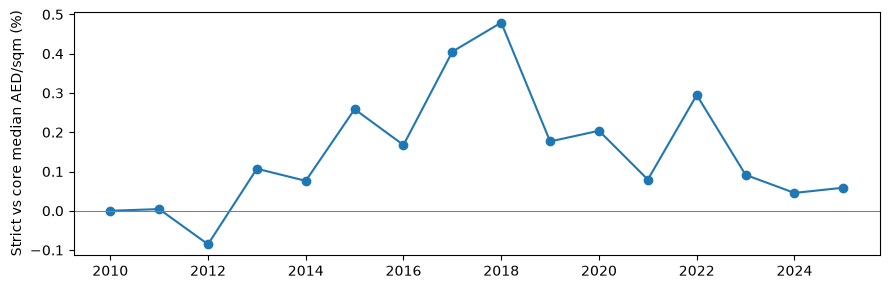

In [12]:
# 16 — Consequences of strict publisher filtering: year-specific eligible medians and coverage
pricing_compare=[]
for y in range(2010,2026):
 yr=analysis_year.eq(y).fillna(False)
 entry={'year':y}
 for tag,flag in [('core','eligible_residential_core'),('strict','eligible_residential_strict')]:
  s=featured.loc[yr&cleaned[flag],'price_per_sqm'].dropna()
  entry[f'{tag}_n']=len(s);entry[f'{tag}_median_psm']=s.median() if len(s) else np.nan
 entry['median_difference_pct']=100*(entry['strict_median_psm']/entry['core_median_psm']-1) if entry['core_median_psm']>0 else np.nan
 pricing_compare.append(entry)
quality_policy_sensitivity=pd.DataFrame(pricing_compare)
display(quality_policy_sensitivity)
fig,ax=plt.subplots(figsize=(9,3));ax.plot(quality_policy_sensitivity.year,quality_policy_sensitivity.median_difference_pct,marker='o')
ax.axhline(0,color='grey',lw=0.8);ax.set_ylabel('Strict vs core median AED/sqm (%)');plt.tight_layout();fig.savefig(figpath/'00_quality_sensitivity.png',dpi=150,bbox_inches='tight');plt.show()

### Cohort decision — reconcile, do not conflate
P1 Strict remains the **default historical residential-pricing population**, with P1 Core retained for quality-flag sensitivity. The exact eligibility funnel is demonstrated above: the simple legacy type/usage mask is not identical to a valid-area/price core. P2 and P3 are *research-specific subsets*, not substitutes for the full residential population; longitudinal and attribute coverage must be disclosed with the correct denominator.

## 04 · Missingness and selection bias
We distinguish (a) incomplete original fields, (b) time-window exclusions, (c) analytic restrictions and (d) observable differences between selected and excluded observations. Associations between missingness and observed characteristics suggest *selection risk*—not proof of MCAR/MAR/MNAR mechanisms.

,rooms_bucket_missing_pct,has_parking_missing_pct,building_name_missing_pct,project_name_missing_pct,master_project_name_missing_pct,area_id_missing_pct,procedure_id_missing_pct,is_pre_registration_missing_pct
period,,,,,,,,
2024,12.9905,0.000,19.6632,9.3526,14.6949,0.0000,0.0000,0.0000
2025,14.6218,0.000,18.2307,8.5492,17.2777,0.0000,0.0000,0.0000
2026,12.3387,32.302,83.7601,8.0781,83.0000,0.1088,19.8265,19.8265


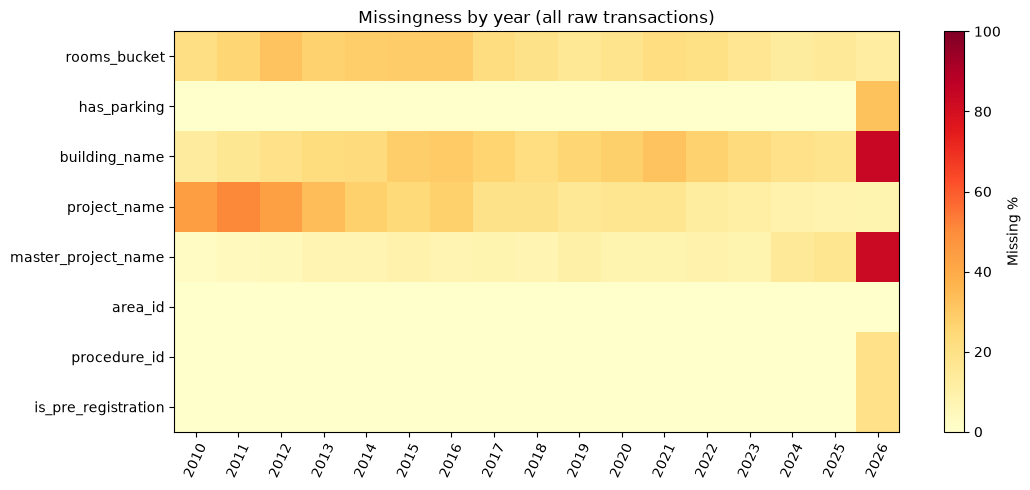

In [13]:
# 19 — Source missingness over time and 2026 metadata break
missing_fields=['rooms_bucket','has_parking','building_name','project_name','master_project_name','area_id','procedure_id','is_pre_registration']
annual_missing=report.yearly_completeness.copy()
assert 'period' in annual_missing and 'transactions' in annual_missing
missingness_matrix=annual_missing.set_index('period')[[f'{x}_missing_pct' for x in missing_fields]]
display(missingness_matrix.loc[[p for p in missingness_matrix.index if p.startswith(('2024','2025','2026'))]])
fig,ax=plt.subplots(figsize=(11,5))
heat=missingness_matrix.loc[[p for p in missingness_matrix.index if p[:4].isdigit() and 2010<=int(p[:4])<=2026]].T
im=ax.imshow(heat.to_numpy(dtype=float),aspect='auto',vmin=0,vmax=100,cmap='YlOrRd');ax.set_yticks(range(len(missing_fields)),missing_fields)
ax.set_xticks(range(len(heat.columns)),[x[:4] for x in heat.columns],rotation=65);fig.colorbar(im,ax=ax,label='Missing %');ax.set_title('Missingness by year (all raw transactions)');plt.tight_layout();fig.savefig(figpath/'00_missingness_heatmap.png',dpi=150,bbox_inches='tight');plt.show()

In [14]:
# 20 — Conditional completeness, including community and registration × property type
segment_missingness=[]
for cols in [['year','property_type_label'],['year','reg_type_label'],
             ['year','usage_label'],['year','reg_type_label','property_type_label'],
             ['year','area_id']]:
 base=featured.loc[featured['year'].between(2010,2026),list(dict.fromkeys(cols+missing_fields))]
 for keys,group in base.groupby(cols,dropna=False,observed=True):
  if len(group)<30 and 'area_id' in cols: continue  # reporting floor only; no data discarded
  d=dict(zip(cols,keys if isinstance(keys,tuple) else (keys,)))
  d.update({'dimension':' × '.join(cols),'n':len(group)})
  d.update({f'{field}_missing_pct':100*group[field].isna().mean() for field in missing_fields})
  segment_missingness.append(d)
missingness_by_segment=pd.DataFrame(segment_missingness)
display(missingness_by_segment.query('year == 2025 and n >= 100').sort_values('n',ascending=False).head(18))

,year,property_type_label,dimension,n,rooms_bucket_missing_pct,has_parking_missing_pct,building_name_missing_pct,project_name_missing_pct,master_project_name_missing_pct,area_id_missing_pct,procedure_id_missing_pct,is_pre_registration_missing_pct,reg_type_label,usage_label,area_id
149,2025,NaN,year × usage_label,191567,5.840254,0.0,13.087849,7.715316,14.263939,0.0,0.0,0.0,NaN,Residential,NaN
62,2025,Unit,year × property_type_label,175643,3.523055,0.0,0.000000,7.211788,10.583969,0.0,0.0,0.0,NaN,NaN,NaN
98,2025,NaN,year × reg_type_label,134384,1.634123,0.0,6.916002,0.000000,15.899214,0.0,0.0,0.0,Off-Plan,NaN,NaN
243,2025,Unit,year × reg_type_label × property_type_label,125090,1.752338,0.0,0.000000,0.000000,13.344792,0.0,0.0,0.0,Off-Plan,NaN,NaN
99,2025,NaN,year × reg_type_label,80419,36.324749,0.0,37.137990,22.835400,19.581193,0.0,0.0,0.0,Ready,NaN,NaN
247,2025,Unit,year × reg_type_label × property_type_label,50553,7.904575,0.0,0.000000,25.056871,3.752497,0.0,0.0,0.0,Ready,NaN,NaN
246,2025,Land,year × reg_type_label × property_type_label,21527,100.000000,0.0,100.000000,13.517908,55.302643,0.0,0.0,0.0,Ready,NaN,NaN
61,2025,Land,year × property_type_label,21527,100.000000,0.0,100.000000,13.517908,55.302643,0.0,0.0,0.0,NaN,NaN,NaN
1207,2025,NaN,year × area_id,18778,3.413569,0.0,2.337842,5.069762,0.000000,0.0,0.0,0.0,NaN,NaN,441.0
63,2025,Villa,year × property_type_label,17011,18.053025,0.0,100.000000,12.938687,36.882018,0.0,0.0,0.0,NaN,NaN,NaN


In [15]:
# 21 — P2 selection: overall AND conditional differences, not a missing-at-random test
reference=cleaned['eligible_residential_strict'] & featured['year'].between(2010,2025).fillna(False)
selected=reference & cleaned['eligible_known_segment']; left_out=reference & ~cleaned['eligible_known_segment']
selection_rows=[]
for field in ['price_per_sqm','area_sqm','price_aed']:
 a=pd.to_numeric(featured.loc[selected,field],errors='coerce').dropna()
 b=pd.to_numeric(featured.loc[left_out,field],errors='coerce').dropna()
 sd=np.sqrt((a.var()+b.var())/2) if len(a)>1 and len(b)>1 else np.nan
 selection_rows.append({'measure':field,'selected_n':len(a),'excluded_n':len(b),
  'selected_median':a.median(),'excluded_median':b.median(),
  'mean_standardized_difference':(a.mean()-b.mean())/sd if sd>0 else np.nan})
selection_bias_diagnostics=pd.DataFrame(selection_rows)
selection_retention=(featured.loc[reference,['year','reg_type_label','property_type_label','area_id']]
 .assign(selected=selected.loc[reference].to_numpy())
 .groupby(['year','reg_type_label','property_type_label'],dropna=False,observed=True)['selected']
 .agg(['size','sum']).reset_index())
selection_retention['retention_pct']=100*selection_retention['sum']/selection_retention['size']
# Comparable subgroups: compare prices/sizes within year × property type × registration.
selection_group_rows=[]
for keys,g in featured.loc[reference,['year','property_type_label','reg_type_label','area_sqm','price_per_sqm']].assign(
 selected=selected.loc[reference].to_numpy()).groupby(['year','property_type_label','reg_type_label'],dropna=False,observed=True):
 inc=g.loc[g.selected];exc=g.loc[~g.selected]
 if min(len(inc),len(exc))<30:continue
 selection_group_rows.append({'year':int(keys[0]),'property_type_label':keys[1], 'reg_type_label':keys[2],
  'selected_n':len(inc),'excluded_n':len(exc),'retention_pct':100*len(inc)/len(g),
  'median_psm_selected':inc.price_per_sqm.median(),'median_psm_excluded':exc.price_per_sqm.median(),
  'median_area_selected':inc.area_sqm.median(),'median_area_excluded':exc.area_sqm.median()})
selection_within_segment=pd.DataFrame(selection_group_rows,columns=['year','property_type_label','reg_type_label','selected_n','excluded_n','retention_pct','median_psm_selected','median_psm_excluded','median_area_selected','median_area_excluded'])
# Community-level retention identifies local geography bias (>=30 for stable reporting only).
selection_community=(featured.loc[reference,['year','area_id']].assign(selected=selected.loc[reference].to_numpy())
 .groupby(['year','area_id'],dropna=False,observed=True)['selected'].agg(['size','sum']).reset_index())
selection_community=selection_community.loc[selection_community['size']>=30].copy()
selection_community['retention_pct']=100*selection_community['sum']/selection_community['size']
display(selection_bias_diagnostics,selection_retention.sort_values('size',ascending=False).head(12),
        selection_within_segment.sort_values('excluded_n',ascending=False).head(12))
print('Differences describe selection on observable fields; missingness mechanism and causal bias remain unproven.')

,measure,selected_n,excluded_n,selected_median,excluded_median,mean_standardized_difference
0,price_per_sqm,864170,37472,1.430448e+04,7.407210e+03,1.197565
1,area_sqm,864170,37472,8.306000e+01,5.145900e+02,-0.701514
2,price_aed,864170,37472,1.241719e+06,3.106350e+06,-0.458921


,year,reg_type_label,property_type_label,size,sum,retention_pct
60,2025,Off-Plan,Unit,119449,119444,99.995814
56,2024,Off-Plan,Unit,92282,92096,99.798444
52,2023,Off-Plan,Unit,56121,56116,99.991091
62,2025,Ready,Unit,43873,43822,99.883755
58,2024,Ready,Unit,41817,41747,99.832604
54,2023,Ready,Unit,36126,36066,99.833915
48,2022,Off-Plan,Unit,34028,34028,100.000000
14,2013,Ready,Unit,32904,32621,99.139922
50,2022,Ready,Unit,27666,27605,99.779513
18,2014,Ready,Unit,25175,25086,99.646475


,year,property_type_label,reg_type_label,selected_n,excluded_n,retention_pct,median_psm_selected,median_psm_excluded,median_area_selected,median_area_excluded
11,2014,Villa,Ready,1277,3935,24.501151,8698.782170,8138.656666,270.230,411.98
9,2013,Villa,Ready,2486,3277,43.137255,7052.300737,5453.736527,345.200,600.06
13,2015,Villa,Ready,945,2808,25.179856,8455.664423,8880.992224,266.450,401.20
18,2017,Villa,Ready,1255,2619,32.395457,8446.969697,8482.671079,255.210,430.33
16,2016,Villa,Ready,963,2541,27.482877,8698.641912,8867.276888,255.020,405.02
24,2021,Villa,Ready,3008,2511,54.502627,8862.232327,7276.471598,259.900,451.45
26,2022,Villa,Ready,3149,2447,56.272337,9503.105590,7809.501118,230.390,476.13
28,2023,Villa,Ready,3895,2371,62.160868,11510.144928,8793.496402,218.030,562.15
6,2012,Villa,Ready,1285,2293,35.913918,7067.415289,4036.466620,255.230,642.30
31,2024,Villa,Ready,4498,2211,67.044269,13819.525216,10702.098015,207.395,561.00


Differences describe selection on observable fields; missingness mechanism and causal bias remain unproven.


In [16]:
# 22 — Amenity exclusions: mutually exclusive statuses and same-period denominators
p1=cleaned['eligible_residential_strict'];historical=featured['year'].between(2015,2025).fillna(False)
known_bedroom=featured['bedroom_label'].notna();known_parking=featured['parking_status'].notna()
base=p1 & historical
amenity_masks={'Bedroom and parking known':base & known_bedroom & known_parking,
 'Bedroom only':base & known_bedroom & ~known_parking,
 'Parking only':base & ~known_bedroom & known_parking,
 'Neither known':base & ~known_bedroom & ~known_parking}
assert sum(int(x.sum()) for x in amenity_masks.values())==int(base.sum())
assert int(amenity_masks['Bedroom and parking known'].sum())==int(cleaned['eligible_amenity_known'].sum())
amenity_overlap=pd.DataFrame([{'group':k,'n':int(m.sum()),
 'share_of_strict_2015_2025_pct':100*m.sum()/base.sum() if base.sum() else np.nan}
 for k,m in amenity_masks.items()])
amenity_reference=pd.DataFrame([{'population':'Strict all years','n':int(p1.sum())},
 {'population':'Strict 2015–2025','n':int(base.sum())},
 {'population':'Strict outside 2015–2025','n':int((p1 & ~historical).sum())}])
if int(base.sum()):
 assert np.isclose(amenity_overlap.share_of_strict_2015_2025_pct.sum(),100)
amenity_annual=(featured.loc[base,['year']].assign(bedroom_known=known_bedroom.loc[base].to_numpy(),
 parking_known=known_parking.loc[base].to_numpy()).groupby('year',observed=True)
 .agg(n=('bedroom_known','size'),bedroom_known_pct=('bedroom_known','mean'),parking_known_pct=('parking_known','mean')).reset_index())
for col in ['bedroom_known_pct','parking_known_pct']:amenity_annual[col]*=100
display(amenity_reference,amenity_overlap,amenity_annual)
print('Bedroom and parking studies should use separate masks; P3 is a combined-feature cohort.')

,population,n
0,Strict all years,1094417
1,Strict 2015–2025,737144
2,Strict outside 2015–2025,357273


,group,n,share_of_strict_2015_2025_pct
0,Bedroom and parking known,712512,96.658455
1,Bedroom only,0,0.000000
2,Parking only,24632,3.341545
3,Neither known,0,0.000000


,year,n,bedroom_known_pct,parking_known_pct
0,2015,31581,90.826763,100.0
1,2016,30762,91.375723,100.0
2,2017,35267,92.403663,100.0
3,2018,24814,94.523253,100.0
4,2019,30661,95.195851,100.0
5,2020,26137,93.748326,100.0
6,2021,46302,94.466762,100.0
7,2022,73415,96.582442,100.0
8,2023,106643,97.708242,100.0
9,2024,152600,98.380734,100.0


Bedroom and parking studies should use separate masks; P3 is a combined-feature cohort.


### Missingness / representativeness decision
Eligibility losses are reported using matching denominators. The selected-versus-excluded comparison is **descriptive**, not proof of a Missing-at-Random mechanism. If bedroom or parking coverage varies by year, community or transaction type, downstream estimates describe only the supported subset; report both the subset and its parent. Separate bedroom-only and parking-only populations are feasible without changing the validated cohort functions.

In [17]:
# 24 — Decode publisher bits and measure flag overlap: not additive row counts
fval=pd.to_numeric(raw['quality_flags'],errors='coerce').fillna(0).astype('int64')
quality_flags_table=fval.value_counts(dropna=False).sort_index().rename_axis('flag_value').reset_index(name='transactions')
bit_table=pd.DataFrame([{'bit':bit,'description':name,'records':int(((fval&bit)!=0).sum())} for bit,name in QUALITY_BITS.items()])
assert quality_flags_table.transactions.sum()==len(raw)
assert quality_flags_table.loc[quality_flags_table.flag_value.ne(0),'transactions'].sum()==(fval!=0).sum()
assert not ((fval & ~sum(QUALITY_BITS))!=0).any(),'Unknown quality flag bits observed'
display(quality_flags_table,bit_table)
flag_year=(pd.DataFrame({'year':featured['year'],'flagged':fval.ne(0)}).groupby('year',dropna=True)['flagged'].agg(['size','sum']).reset_index())
flag_year['flagged_pct']=100*flag_year['sum']/flag_year['size'];display(flag_year.tail(10))

,flag_value,transactions
0,0,1354155
1,1,10
2,2,737
3,3,38
4,4,27356
5,5,264
6,6,172
7,7,115
8,16,1


,bit,description,records
0,1,low_price,427
1,2,invalid_area,1062
2,4,psf_outlier,27907
3,8,missing_both_core_values,0
4,16,invalid_date,1


,year,size,sum,flagged_pct
24,2017,46230,965,2.087389
25,2018,32194,722,2.242654
26,2019,36925,631,1.708869
27,2020,33102,684,2.066340
28,2021,59424,1209,2.034532
29,2022,95471,2031,2.127348
30,2023,131801,2706,2.053095
31,2024,179416,3669,2.044968
32,2025,214803,4365,2.032095
33,2026,136035,2804,2.061234


In [18]:
# 25 — Price mathematics: missing, nonpositive and discrepancy are separate failure classes
p=pd.to_numeric(raw['price_aed'],errors='coerce');a=pd.to_numeric(raw['area_sqm'],errors='coerce');s=pd.to_numeric(raw['price_psf'],errors='coerce')
valid_base=np.isfinite(p)&np.isfinite(a)&p.gt(0)&a.gt(0)
expected=(p[valid_base]/(a[valid_base]*SQFT_PER_SQM))
source_valid=valid_base&s.notna()&np.isfinite(s)
calc=(p[source_valid]/(a[source_valid]*SQFT_PER_SQM))
diff=(s[source_valid]-calc).abs(); rel=diff/calc*100
bad=(diff>0.01)&(rel>1.0)
psf_checks=pd.DataFrame([{'missing_source_psf':int(s.isna().sum()),'nonpositive_source_psf':int((s.notna() & s.le(0)).sum()),
                          'invalid_price_or_area_for_psm':int((~valid_base).sum()),
                          'price_psf_comparable_n':int(source_valid.sum()),'mismatches_above_validator_tolerance':int(bad.sum()),
                          'missing_psf_with_nonzero_flags':int((s.isna()&fval.ne(0)).sum()),
                          'nonpositive_psf_with_nonzero_flags':int((s.notna()&s.le(0)&fval.ne(0)).sum())}])
assert np.allclose(featured.loc[valid_base,'price_per_sqm'].to_numpy(),(p[valid_base]/a[valid_base]).to_numpy(),rtol=1e-12)
assert featured.loc[~valid_base,'price_per_sqm'].isna().all()
display(psf_checks)

,missing_source_psf,nonpositive_source_psf,invalid_price_or_area_for_psm,price_psf_comparable_n,mismatches_above_validator_tolerance,missing_psf_with_nonzero_flags,nonpositive_psf_with_nonzero_flags
0,186,24,2,1382662,0,186,24


In [19]:
# 26 — Segment-level publisher-flag sensitivity, not a duplicate of Cell 16
quality_comparison=[]
for (year,property_type,registration),group in featured.loc[featured.year.between(2010,2025) &
 cleaned.eligible_residential_core, ['year','property_type_label','reg_type_label','price_per_sqm']].assign(
 strict=cleaned.loc[featured.year.between(2010,2025)&cleaned.eligible_residential_core,
 'eligible_residential_strict'].to_numpy()).groupby(['year','property_type_label','reg_type_label'],observed=True):
 core_psm=group.price_per_sqm.dropna();strict_psm=group.loc[group.strict,'price_per_sqm'].dropna()
 if len(core_psm)<30 or len(strict_psm)<30:continue
 quality_comparison.append({'year':int(year),'property_type':property_type,'registration':registration,
 'core_n':len(core_psm),'strict_n':len(strict_psm),
 'flag_exclusion_pct':100*(1-len(strict_psm)/len(core_psm)),
 'core_median_psm':core_psm.median(),'strict_median_psm':strict_psm.median(),
 'median_change_pct':100*(strict_psm.median()/core_psm.median()-1) if core_psm.median()>0 else np.nan,
 'core_p25':core_psm.quantile(.25),'strict_p25':strict_psm.quantile(.25),
 'core_p75':core_psm.quantile(.75),'strict_p75':strict_psm.quantile(.75)})
quality_segment_sensitivity=pd.DataFrame(quality_comparison)
display(quality_segment_sensitivity.sort_values('median_change_pct',key=lambda s:s.abs(),ascending=False).head(15))
print('Citywide annual results remain in Cell 16; this table checks segment-level sensitivity.')

,year,property_type,registration,core_n,strict_n,flag_exclusion_pct,core_median_psm,strict_median_psm,median_change_pct,core_p25,strict_p25,core_p75,strict_p75
14,2013,Villa,Ready,5877,5763,1.939765,5690.244106,5760.333333,1.231744,3229.172934,3336.731091,8669.354839,8676.979283
10,2012,Villa,Ready,3653,3578,2.053107,4785.555556,4828.116663,0.889366,2853.495935,2924.998749,6985.027716,6965.862901
27,2017,Unit,Off-Plan,16901,16713,1.112360,12929.246370,13002.272727,0.564815,9689.042448,9795.121519,17025.611176,17088.124649
62,2025,Villa,Ready,6606,6527,1.195883,14942.528736,15015.974441,0.491521,11713.747395,11846.940791,18501.154229,18523.927145
22,2015,Villa,Ready,3812,3753,1.547744,8733.484775,8775.132320,0.476872,6309.830384,6416.426051,10442.300889,10443.003188
30,2017,Villa,Ready,3943,3874,1.749937,8436.213992,8474.354548,0.452105,6374.689867,6451.946987,9419.862389,9420.739994
11,2013,Unit,Off-Plan,6843,6748,1.388280,14770.087829,14836.579938,0.450181,9533.260898,9748.344647,19949.550892,19943.803571
54,2023,Villa,Ready,6347,6266,1.276193,10530.195335,10575.758742,0.432693,8184.111584,8279.126339,13640.228309,13671.468452
36,2019,Unit,Ready,9347,9253,1.005670,9003.939223,9041.702546,0.419409,6419.558268,6458.351462,12211.131238,12211.740614
39,2020,Unit,Off-Plan,10441,10336,1.005651,14475.368899,14536.031418,0.419074,10477.134362,10572.460866,18208.396679,18245.360172


Citywide annual results remain in Cell 16; this table checks segment-level sensitivity.


### Price QA interpretation
Publisher zero-flag status is a screening rule, **not** proof of fair value. Do not recalculate a missing `price_psf` into the source column, remove nominal sales from transaction counts simply because price is small, or treat percentile outliers as typos. The observed flag sensitivity determines what limitations follow a pricing estimate.

,year,transactions,months_observed,primary_year,provisional_2026,months_12_observed
15,2008,23634,12,False,False,True
16,2009,62947,12,False,False,True
17,2010,34120,12,True,False,True
18,2011,28439,12,True,False,True
19,2012,36479,12,True,False,True
20,2013,64517,12,True,False,True
21,2014,56018,12,True,False,True
22,2015,42882,12,True,False,True
23,2016,42692,12,True,False,True
24,2017,46230,12,True,False,True


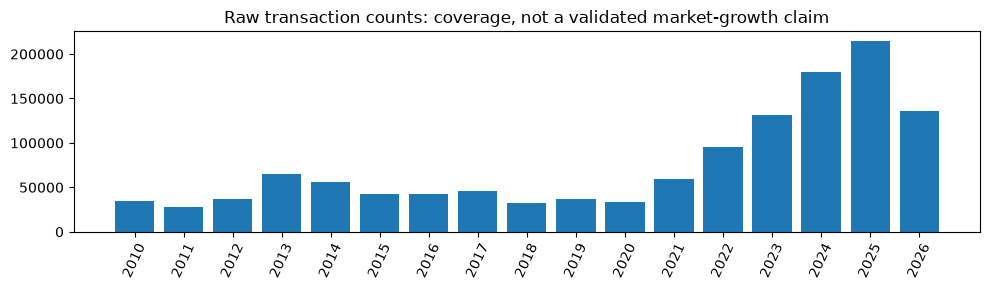

In [20]:
# 28 — Full-year vs partial-year coverage and provisional 2026
calendar=(featured.loc[featured['year'].notna(),['year','month']]
          .groupby('year',observed=True)['month'].agg(transactions='size',months_observed='nunique').reset_index())
calendar['primary_year']=calendar.year.between(2010,2025)
calendar['provisional_2026']=calendar.year.eq(2026)
calendar['months_12_observed']=calendar.months_observed.eq(12)
display(calendar.query('year >= 2008'))
assert calendar.loc[calendar.year.eq(2026),'provisional_2026'].all()
fig,ax=plt.subplots(figsize=(10,3));sub=calendar.query('year >= 2010');ax.bar(sub.year.astype(str),sub.transactions)
ax.set_title('Raw transaction counts: coverage, not a validated market-growth claim');ax.tick_params(axis='x',rotation=65);plt.tight_layout();plt.show()

In [21]:
# 29 — Geographic continuity and stable identifiers; endpoint presence != comparability
geo=featured.loc[featured.year.between(2010,2025)&cleaned.eligible_residential_strict,
 ['area_id','area_name_en','year','transaction_id']].copy()
geo_missing=int(geo.area_id.isna().sum())
area_coverage=geo.loc[geo.area_id.notna()].groupby(['area_id','year'],observed=True).size().rename('n').reset_index()
area_summary=(area_coverage.groupby('area_id',observed=True).agg(first_year=('year','min'),
 last_year=('year','max'),years_with_sales=('year','nunique'),total_sales=('n','sum')).reset_index())
area_summary['endpoint_2021']=area_summary.area_id.isin(area_coverage.loc[area_coverage.year.eq(2021),'area_id'])
area_summary['endpoint_2025']=area_summary.area_id.isin(area_coverage.loc[area_coverage.year.eq(2025),'area_id'])
area_summary['present_both_endpoints']=area_summary.endpoint_2021&area_summary.endpoint_2025
for yr in [2021,2025]:
 counts=area_coverage.loc[area_coverage.year.eq(yr),['area_id','n']].rename(columns={'n':f'n_{yr}'})
 area_summary=area_summary.merge(counts,on='area_id',how='left',validate='one_to_one')
 area_summary[f'n_{yr}']=area_summary[f'n_{yr}'].fillna(0).astype(int)
area_summary['endpoint_30_each']=(area_summary.n_2021>=30)&(area_summary.n_2025>=30)
area_summary['consistent_10_years']=area_summary.years_with_sales>=10
geography_coverage=area_summary
mapping_exceptions=report.area_mapping.copy()
geo_summary=pd.DataFrame([{'strict_residential_2010_2025_rows':len(geo),'missing_area_id_rows':geo_missing,
 'areas_observed':len(area_summary),'areas_both_endpoints':int(area_summary.present_both_endpoints.sum()),
 'areas_30_each_endpoint':int(area_summary.endpoint_30_each.sum()),
 'areas_10_plus_years':int(area_summary.consistent_10_years.sum()),
 'ambiguous_source_mapping_rows':len(mapping_exceptions)}])
display(geo_summary,area_summary.sort_values('total_sales',ascending=False).head(12))

,strict_residential_2010_2025_rows,missing_area_id_rows,areas_observed,areas_both_endpoints,areas_30_each_endpoint,areas_10_plus_years,ambiguous_source_mapping_rows
0,901642,0,127,95,53,96,0


,area_id,first_year,last_year,years_with_sales,total_sales,endpoint_2021,endpoint_2025,present_both_endpoints,n_2021,n_2025,endpoint_30_each,consistent_10_years
38,330.0,2010,2025,16,79607,True,True,True,5460,6558,True,True
92,441.0,2010,2025,16,75646,True,True,True,3235,17735,True,True
123,526.0,2010,2025,16,55100,True,True,True,3908,11499,True,True
69,390.0,2010,2025,16,48413,True,True,True,2294,3790,True,True
109,467.0,2010,2025,16,37346,True,True,True,2536,10883,True,True
50,350.0,2010,2025,16,36129,True,True,True,2494,3815,True,True
84,412.0,2015,2025,11,30900,True,True,True,2331,3095,True,True
113,482.0,2014,2025,12,29995,True,True,True,2437,4555,True,True
48,343.0,2010,2025,16,29513,True,True,True,1321,1758,True,True
90,435.0,2010,2025,16,28356,True,True,True,1964,3469,True,True


In [22]:
# 30 — Registration/procedure completeness and classification denominators
reg_detail=featured.loc[featured.year.between(2010,2026),
 ['year','reg_type_label','procedure_id','procedure_name_en','is_pre_registration']].copy()
reg_detail['procedure_complete']=reg_detail[['procedure_id','procedure_name_en','is_pre_registration']].notna().all(axis=1)
registration_consistency=(reg_detail.groupby(['year','reg_type_label','procedure_complete'],dropna=False,observed=True)
 .size().rename('n').reset_index())
registration_coverage=(reg_detail.groupby(['year','reg_type_label'],dropna=False,observed=True)
 .agg(n=('procedure_complete','size'),procedure_complete_n=('procedure_complete','sum')).reset_index())
registration_coverage['procedure_complete_pct']=100*registration_coverage.procedure_complete_n/registration_coverage.n
assert registration_consistency.n.sum()==len(reg_detail)
display(registration_consistency.query('year >= 2025'),registration_coverage.query('year >= 2025'))
print('Ready denotes registration class, not verified resale; incomplete metadata alone does not prove misclassification.')

,year,reg_type_label,procedure_complete,n
30,2025,Off-Plan,True,134384
31,2025,Ready,True,80419
32,2026,Off-Plan,True,91404
33,2026,Ready,False,26971
34,2026,Ready,True,17660


,year,reg_type_label,n,procedure_complete_n,procedure_complete_pct
30,2025,Off-Plan,134384,134384,100.00000
31,2025,Ready,80419,80419,100.00000
32,2026,Off-Plan,91404,91404,100.00000
33,2026,Ready,44631,17660,39.56891


Ready denotes registration class, not verified resale; incomplete metadata alone does not prove misclassification.


### Temporal / geographic interpretation
The primary research period is 2010–2025; 2026 is provisional because of partial-year coverage and a metadata-completeness discontinuity. Observed months do not establish complete administrative reporting. Ready does not prove resale. An `area_id` present at both endpoints does not guarantee matched property composition or adequate sample sizes; coverage at each endpoint must be assessed before estimating trends.

## 07 · Evidence-based feasibility assessment (not a research-results verdict)
For every RQ, test **source-field presence, complete records relative to a declared parent, time breadth, and relevant group/sample support**. Direct citywide questions and quarterly/community/matching questions need different support tests. Criteria are specified before the results are used: at least 8 observed primary years and 200 usable observations in each of those years for broad historical trends; 30 transactions per group for informative endpoint/community screening; at least 8 years with 4 observed quarters for exploratory lead-lag feasibility. These are **planning safeguards, not statistical power guarantees**. Low coverage is CONDITIONAL rather than a fabricated PASS; absent data or completely unsupported comparisons are NO_GO. Inferential conclusions remain methodologically unvalidated regardless of input PASS.

In [23]:

# 33 — Evidence-based research input feasibility
# These checks assess DATA SUPPORT, not inferential validity.

rq_specs = [
    ("RQ01", "eligible_known_segment",
     ["area_id", "property_type_label", "reg_type_label",
      "rooms_bucket", "area_sqm", "price_per_sqm"], "matched"),
    ("RQ02", "eligible_residential_strict",
     ["property_type_label", "rooms_bucket", "area_sqm", "year"], "yearly"),
    ("RQ03", "eligible_residential_strict",
     ["price_aed", "area_sqm", "area_id", "year"], "yearly"),
    ("RQ04", "eligible_market_activity",
     ["area_id", "year", "transaction_id"], "community"),
    ("RQ05", "eligible_market_activity",
     ["reg_type_label", "price_aed", "year"], "registration"),
    ("RQ06", "eligible_residential_strict",
     ["area_id", "year", "quarter", "price_per_sqm"], "quarterly"),
    ("RQ07", "eligible_known_segment",
     ["area_id", "property_type_label", "rooms_bucket",
      "year", "price_per_sqm"], "community"),
    ("RQ08", "eligible_residential_strict",
     ["area_id", "year", "price_per_sqm"], "community"),
    ("RQ09", "eligible_residential_strict",
     ["area_id", "year", "price_per_sqm"], "community"),
    ("RQ10", "eligible_residential_strict",
     ["area_sqm", "price_per_sqm", "rooms_bucket", "year"], "yearly"),
    ("RQ11", "eligible_known_segment",
     ["reg_type_label", "area_id", "rooms_bucket",
      "area_sqm", "price_per_sqm"], "paired_registration"),
    ("RQ12", "eligible_residential_strict",
     ["price_per_sqm", "year"], "amenity"),
    ("RQ13", "eligible_residential_strict",
     ["area_id", "year", "price_per_sqm"], "community"),
    ("RQ14", "eligible_residential_strict",
     ["price_aed", "year"], "yearly"),
    ("RQ15", "eligible_market_activity",
     ["quality_flags", "year", "area_id"], "yearly")
]

primary = featured["year"].between(2010, 2025).fillna(False)
quality_parent = cleaned["eligible_residential_strict"] & primary
activity_parent = cleaned["eligible_market_activity"] & primary

# Transparent planning thresholds.
# These screen usable data, not statistical significance.
MIN_YEAR_OBSERVATIONS = 200
MIN_SUPPORTED_YEARS = 8
MIN_COMMUNITIES = 5
MIN_GROUP_SIZE = 30
MIN_AMENITY_GROUP_SIZE = 20
MIN_AMENITY_COMPARISONS = 10
MIN_CONTINUOUS_QUARTERS = 8
MIN_QUARTER_OBSERVATIONS = 10
MIN_SOURCE_COVERAGE = 0.60

def paired_group_count(frame, keys, category, left, right, minimum):
    if frame.empty:
        return 0
    counts = (
        frame.groupby(keys + [category], observed=True, dropna=False)
        .size()
        .unstack(category, fill_value=0)
    )
    for value in (left, right):
        if value not in counts.columns:
            counts[value] = 0
    return int(
        ((counts[left] >= minimum) &
         (counts[right] >= minimum)).sum()
    )

# RQ12: count ACTUAL comparable groups rather than observations.
amenity_base = quality_parent & featured["year"].between(
    2015, 2025
).fillna(False)

parking_data = featured.loc[
    amenity_base & featured["parking_status"].isin(["Yes", "No"]),
    ["year", "area_id", "property_type_label",
     "reg_type_label", "parking_status"]
].dropna()

bedroom_data = featured.loc[
    amenity_base & featured["rooms_bucket"].isin([1, 2]),
    ["year", "area_id", "property_type_label",
     "reg_type_label", "rooms_bucket"]
].dropna()

comparison_keys = [
    "year", "area_id", "property_type_label", "reg_type_label"
]

parking_groups = paired_group_count(
    parking_data, comparison_keys,
    "parking_status", "Yes", "No",
    MIN_AMENITY_GROUP_SIZE
)

bedroom_groups = paired_group_count(
    bedroom_data, comparison_keys,
    "rooms_bucket", 1, 2,
    MIN_AMENITY_GROUP_SIZE
)

amenity_support = pd.DataFrame([
    {
        "comparison": "Parking Yes vs No",
        "usable_transactions": len(parking_data),
        "comparable_groups": parking_groups,
        "minimum_per_side": MIN_AMENITY_GROUP_SIZE
    },
    {
        "comparison": "1BR vs 2BR",
        "usable_transactions": len(bedroom_data),
        "comparable_groups": bedroom_groups,
        "minimum_per_side": MIN_AMENITY_GROUP_SIZE
    }
])

# RQ06: require continuous, adequately populated community quarters.
quarter_data = featured.loc[
    quality_parent &
    featured["area_id"].notna() &
    featured["quarter"].notna(),
    ["area_id", "year", "quarter"]
].copy()

quarter_data["period_index"] = (
    quarter_data["year"].astype(int) * 4 +
    quarter_data["quarter"].astype(int)
)

quarter_counts = (
    quarter_data.groupby(
        ["area_id", "period_index"], observed=True
    )
    .size()
    .rename("n")
    .reset_index()
)

def longest_consecutive_run(values):
    values = sorted(set(int(v) for v in values))
    longest = current = 0
    previous = None
    for value in values:
        current = current + 1 if previous == value - 1 else 1
        longest = max(longest, current)
        previous = value
    return longest

quarterly_support = (
    quarter_counts.loc[
        quarter_counts["n"] >= MIN_QUARTER_OBSERVATIONS
    ]
    .groupby("area_id", observed=True)["period_index"]
    .apply(longest_consecutive_run)
)

continuous_communities = int(
    (quarterly_support >= MIN_CONTINUOUS_QUARTERS).sum()
)

feasibility_rows = []

for rq, population, required, design in rq_specs:

    parent = (
        activity_parent if population == "eligible_market_activity"
        else quality_parent
    )

    candidate = cleaned[population] & primary
    absent = sorted(set(required) - set(featured.columns))

    if absent:
        usable = pd.Series(False, index=featured.index)
    else:
        usable = candidate & featured[required].notna().all(axis=1)

    if design == "amenity":
        candidate = amenity_base
        usable = candidate & (
            featured["bedroom_label"].notna() |
            featured["parking_status"].notna()
        )

    n = int(usable.sum())
    parent_n = int(parent.sum())
    candidate_n = int(candidate.sum())

    year_counts = (
        featured.loc[usable]
        .groupby("year", observed=True)
        .size()
    )
    years = len(year_counts)
    years_200 = int(
        (year_counts >= MIN_YEAR_OBSERVATIONS).sum()
    )
    communities = int(
        featured.loc[usable, "area_id"].nunique()
    )

    support_n = 0
    support_definition = ""
    support_ok = False

    if design == "matched":
        # Resolved from calculated endpoint support in Cell 34.
        support_definition = "Pending endpoint matching screen"

    elif design == "paired_registration":
        subset = featured.loc[
            usable & featured["year"].isin([2021, 2025]),
            ["year", "area_id", "reg_type_label"]
        ].dropna()

        support_n = paired_group_count(
            subset, ["year", "area_id"],
            "reg_type_label", "Ready", "Off-Plan",
            MIN_GROUP_SIZE
        )
        support_ok = support_n >= MIN_AMENITY_COMPARISONS
        support_definition = "Area-year Ready/Off-Plan pairs"

    elif design == "community":
        subset = featured.loc[
            usable & featured["year"].isin([2021, 2025]),
            ["area_id", "year"]
        ].dropna()

        counts = (
            subset.groupby(["area_id", "year"], observed=True)
            .size()
            .unstack("year", fill_value=0)
        )
        for year in (2021, 2025):
            if year not in counts.columns:
                counts[year] = 0

        support_n = int(
            ((counts[2021] >= MIN_GROUP_SIZE) &
             (counts[2025] >= MIN_GROUP_SIZE)).sum()
        )
        support_ok = support_n >= MIN_COMMUNITIES
        support_definition = "Communities with 30+ in both years"

    elif design == "quarterly":
        support_n = continuous_communities
        support_ok = support_n >= MIN_COMMUNITIES
        support_definition = (
            "Communities with 8 consecutive quarters, "
            "10+ transactions per quarter"
        )

    elif design == "registration":
        subset = featured.loc[
            usable, ["year", "reg_type_label"]
        ].dropna()

        support_n = paired_group_count(
            subset, ["year"], "reg_type_label",
            "Ready", "Off-Plan", MIN_GROUP_SIZE
        )
        support_ok = support_n >= MIN_SUPPORTED_YEARS
        support_definition = "Years with both registration classes"

    elif design == "amenity":
        support_n = min(parking_groups, bedroom_groups)
        support_ok = (
            parking_groups >= MIN_AMENITY_COMPARISONS and
            bedroom_groups >= MIN_AMENITY_COMPARISONS
        )
        support_definition = (
            f"Parking groups={parking_groups}; "
            f"bedroom groups={bedroom_groups}"
        )

    else:
        support_n = years_200
        support_ok = years_200 >= MIN_SUPPORTED_YEARS
        support_definition = "Years with 200+ usable transactions"

    coverage = n / parent_n if parent_n else 0

    if absent or n == 0 or parent_n == 0:
        gate = "NO_GO"
    elif design == "matched":
        gate = "PENDING_MATCHING"
    elif (
        not support_ok or
        years_200 < MIN_SUPPORTED_YEARS or
        coverage < MIN_SOURCE_COVERAGE
    ):
        gate = "CONDITIONAL"
    else:
        gate = "PASS"

    feasibility_rows.append({
        "rq": rq,
        "design": design,
        "cohort": population,
        "primary_period": "2010-2025",
        "reference_parent_n": parent_n,
        "eligible_cohort_n": candidate_n,
        "usable_n": n,
        "source_parent_coverage_pct":
            100 * coverage if parent_n else np.nan,
        "within_cohort_complete_pct":
            100 * n / candidate_n if candidate_n else np.nan,
        "years_observed": years,
        "years_with_200_plus": years_200,
        "communities": communities,
        "support_groups": support_n,
        "minimum_support_groups":
            MIN_AMENITY_COMPARISONS if design in
            ("paired_registration", "amenity") else (
                MIN_COMMUNITIES if design in
                ("community", "quarterly") else
                MIN_SUPPORTED_YEARS
            ),
        "missing_required_fields": "; ".join(absent),
        "support_definition": support_definition,
        "input_gate_pre_matching": gate
    })

feasibility_gate = pd.DataFrame(feasibility_rows)

assert len(feasibility_gate) == 15
assert feasibility_gate["rq"].is_unique
assert feasibility_gate["input_gate_pre_matching"].isin(
    ["PASS", "CONDITIONAL", "NO_GO", "PENDING_MATCHING"]
).all()

display(amenity_support)
print("Communities with continuous quarterly support:",
      continuous_communities)
display(feasibility_gate)

print(
    "These gates measure data availability and group support. "
    "They do not establish causal validity, comparability, "
    "predictive accuracy, or statistically significant findings."
)


,comparison,usable_transactions,comparable_groups,minimum_per_side
0,Parking Yes vs No,737144,97,20
1,1BR vs 2BR,443824,622,20


Communities with continuous quarterly support: 65


,rq,design,cohort,primary_period,reference_parent_n,eligible_cohort_n,usable_n,source_parent_coverage_pct,within_cohort_complete_pct,years_observed,years_with_200_plus,communities,support_groups,minimum_support_groups,missing_required_fields,support_definition,input_gate_pre_matching
0,RQ01,matched,eligible_known_segment,2010-2025,901642,864170,864170,95.844027,100.000000,16,16,76,0,8,,Pending endpoint matching screen,PENDING_MATCHING
1,RQ02,yearly,eligible_residential_strict,2010-2025,901642,901642,864170,95.844027,95.844027,16,16,76,16,8,,Years with 200+ usable transactions,PASS
2,RQ03,yearly,eligible_residential_strict,2010-2025,901642,901642,901642,100.000000,100.000000,16,16,127,16,8,,Years with 200+ usable transactions,PASS
3,RQ04,community,eligible_market_activity,2010-2025,1134513,1134513,1134513,100.000000,100.000000,16,16,203,63,5,,Communities with 30+ in both years,PASS
4,RQ05,registration,eligible_market_activity,2010-2025,1134513,1134513,1134513,100.000000,100.000000,16,16,203,16,8,,Years with both registration classes,PASS
5,RQ06,quarterly,eligible_residential_strict,2010-2025,901642,901642,901642,100.000000,100.000000,16,16,127,65,5,,"Communities with 8 consecutive quarters, 10+ t...",PASS
6,RQ07,community,eligible_known_segment,2010-2025,901642,864170,864170,95.844027,100.000000,16,16,76,53,5,,Communities with 30+ in both years,PASS
7,RQ08,community,eligible_residential_strict,2010-2025,901642,901642,901642,100.000000,100.000000,16,16,127,53,5,,Communities with 30+ in both years,PASS
8,RQ09,community,eligible_residential_strict,2010-2025,901642,901642,901642,100.000000,100.000000,16,16,127,53,5,,Communities with 30+ in both years,PASS
9,RQ10,yearly,eligible_residential_strict,2010-2025,901642,901642,864170,95.844027,95.844027,16,16,76,16,8,,Years with 200+ usable transactions,PASS


These gates measure data availability and group support. They do not establish causal validity, comparability, predictive accuracy, or statistically significant findings.


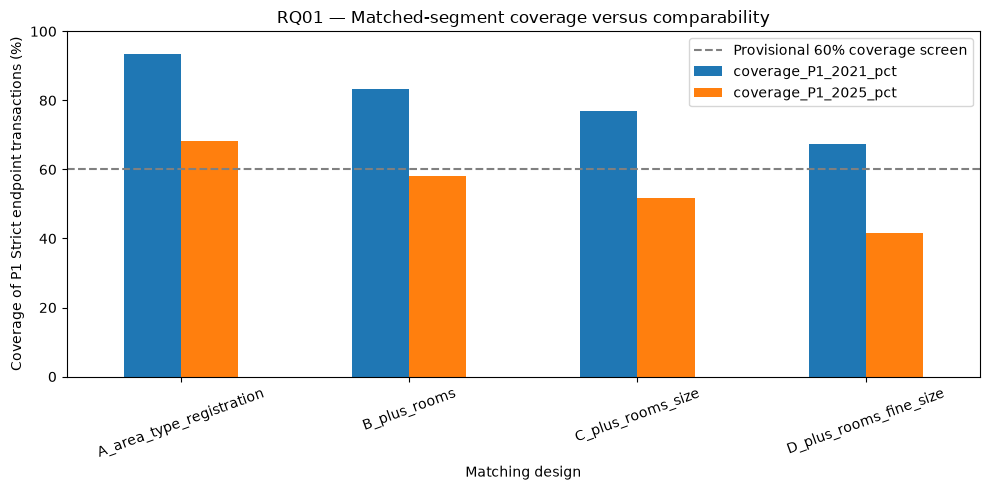

,design,minimum_per_year,matched_cells,matched_2021_n,eligible_P2_2021_n,eligible_P1_2021_n,coverage_P2_2021_pct,coverage_P1_2021_pct,matched_2025_n,eligible_P2_2025_n,eligible_P1_2025_n,coverage_P2_2025_pct,coverage_P1_2025_pct,input_support_pass
1,A_area_type_registration,30,95,43244,43740,46302,98.866027,93.395534,121891,177011,178962,68.860692,68.109990,True
5,B_plus_rooms,30,200,38525,43740,46302,88.077275,83.203749,103902,177011,178962,58.698047,58.058135,False
9,C_plus_rooms_size,30,234,35568,43740,46302,81.316872,76.817416,92508,177011,178962,52.261159,51.691421,False
13,D_plus_rooms_fine_size,30,242,31143,43740,46302,71.200274,67.260593,74212,177011,178962,41.925078,41.468021,False


,rq,design,cohort,primary_period,reference_parent_n,eligible_cohort_n,usable_n,source_parent_coverage_pct,within_cohort_complete_pct,years_observed,years_with_200_plus,communities,support_groups,minimum_support_groups,missing_required_fields,support_definition,input_gate_pre_matching
0,RQ01,matched,eligible_known_segment,2010-2025,901642,864170,864170,95.844027,100.0,16,16,76,242,30,,Endpoint matched-cell screen: 1 of 4 designs m...,PASS


RQ01 input status: PASS
RQ01 methodological status: COMPARABILITY_AND_COVERAGE_TRADEOFF_UNRESOLVED
Matching feasibility does not establish a representative or statistically valid price index.


In [24]:

# 34 — Matched-segment coverage and final RQ01 input decision

base = featured.loc[
    cleaned["eligible_known_segment"] &
    featured["year"].isin([2021, 2025])
].copy()

base["size_group_coarse"] = pd.cut(
    base["area_sqm"],
    bins=[0, 60, 100, 150, np.inf],
    labels=["<=60", "60-100", "100-150", ">150"]
)

base["size_group_fine"] = pd.cut(
    base["area_sqm"],
    bins=[0, 45, 60, 80, 100, 130, 170, 250, np.inf]
)

matching_designs = {
    "A_area_type_registration": [
        "area_id", "property_type_label", "reg_type_label"
    ],
    "B_plus_rooms": [
        "area_id", "property_type_label",
        "reg_type_label", "rooms_bucket"
    ],
    "C_plus_rooms_size": [
        "area_id", "property_type_label",
        "reg_type_label", "rooms_bucket",
        "size_group_coarse"
    ],
    "D_plus_rooms_fine_size": [
        "area_id", "property_type_label",
        "reg_type_label", "rooms_bucket",
        "size_group_fine"
    ]
}

matching_rows = []

for design, keys in matching_designs.items():

    valid = base.dropna(subset=keys)

    counts = (
        valid.groupby(keys + ["year"], observed=True)
        .size()
        .unstack("year", fill_value=0)
    )

    for year in (2021, 2025):
        if year not in counts.columns:
            counts[year] = 0

    for threshold in (20, 30, 50, 100):

        matched = (
            counts[2021].ge(threshold) &
            counts[2025].ge(threshold)
        )

        row = {
            "design": design,
            "minimum_per_year": threshold,
            "matched_cells": int(matched.sum())
        }

        for year in (2021, 2025):

            matched_n = int(counts.loc[matched, year].sum())

            p2_n = int((base["year"] == year).sum())

            p1_n = int((
                cleaned["eligible_residential_strict"] &
                featured["year"].eq(year)
            ).sum())

            row.update({
                f"matched_{year}_n": matched_n,
                f"eligible_P2_{year}_n": p2_n,
                f"eligible_P1_{year}_n": p1_n,
                f"coverage_P2_{year}_pct":
                    100 * matched_n / p2_n if p2_n else np.nan,
                f"coverage_P1_{year}_pct":
                    100 * matched_n / p1_n if p1_n else np.nan
            })

        matching_rows.append(row)

matching_feasibility = pd.DataFrame(matching_rows)

coverage_columns = [
    c for c in matching_feasibility.columns
    if c.startswith("coverage_")
]

for col in coverage_columns:
    assert matching_feasibility[col].dropna().between(
        0, 100.00001
    ).all(), col

# Primary feasibility screen: 30 transactions per segment
# in BOTH endpoint years, >=30 matched cells, and >=60%
# coverage of the wider P1 Strict population at each endpoint.

primary_screen = matching_feasibility.loc[
    matching_feasibility["minimum_per_year"].eq(30)
].copy()

primary_screen["input_support_pass"] = (
    primary_screen["matched_cells"].ge(30) &
    primary_screen["coverage_P1_2021_pct"].ge(60) &
    primary_screen["coverage_P1_2025_pct"].ge(60)
)

adequate = primary_screen.loc[
    primary_screen["input_support_pass"]
].copy()

# Stronger descriptive comparability requires more than
# area/type/registration. Test this separately.
controlled_designs = primary_screen.loc[
    primary_screen["design"].isin([
        "B_plus_rooms",
        "C_plus_rooms_size",
        "D_plus_rooms_fine_size"
    ])
]

controlled_support = controlled_designs.loc[
    controlled_designs["input_support_pass"]
]

rq01_index = feasibility_gate.index[
    feasibility_gate["rq"].eq("RQ01")
][0]

rq01 = feasibility_gate.loc[rq01_index]

source_supported = (
    rq01["usable_n"] > 0 and
    rq01["years_with_200_plus"] >= MIN_SUPPORTED_YEARS and
    rq01["source_parent_coverage_pct"] >=
        100 * MIN_SOURCE_COVERAGE and
    not rq01["missing_required_fields"]
)

if not source_supported:
    final_rq01_status = "CONDITIONAL"
elif adequate.empty:
    final_rq01_status = "CONDITIONAL"
else:
    final_rq01_status = "PASS"

feasibility_gate.loc[
    rq01_index, "input_gate_pre_matching"
] = final_rq01_status

feasibility_gate.loc[
    rq01_index, "support_groups"
] = int(primary_screen["matched_cells"].max())

feasibility_gate.loc[
    rq01_index, "minimum_support_groups"
] = 30

feasibility_gate.loc[
    rq01_index, "support_definition"
] = (
    f"Endpoint matched-cell screen: "
    f"{len(adequate)} of {len(primary_screen)} designs "
    f"meet basic input criteria; "
    f"{len(controlled_support)} designs also include bedrooms; "
    "method selection remains unvalidated"
)

# An input PASS is not permission to publish an index.
rq01_method_status = (
    "CANDIDATE_CONTROLLED_DESIGN_AVAILABLE"
    if not controlled_support.empty
    else "COMPARABILITY_AND_COVERAGE_TRADEOFF_UNRESOLVED"
)

# Plot endpoint coverage against the broad residential population.
fig, ax = plt.subplots(figsize=(10, 5))

plot_data = primary_screen.set_index("design")

plot_data[
    ["coverage_P1_2021_pct", "coverage_P1_2025_pct"]
].plot(kind="bar", ax=ax)

ax.axhline(
    60, linestyle="--", color="gray",
    label="Provisional 60% coverage screen"
)

ax.set_ylabel("Coverage of P1 Strict endpoint transactions (%)")
ax.set_xlabel("Matching design")
ax.set_ylim(0, 100)
ax.set_title("RQ01 — Matched-segment coverage versus comparability")
ax.tick_params(axis="x", rotation=20)
ax.legend()

plt.tight_layout()
fig.savefig(
    figpath / "00_matching_coverage.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

display(primary_screen)
display(feasibility_gate.loc[
    feasibility_gate["rq"].eq("RQ01")
])

print("RQ01 input status:", final_rq01_status)
print("RQ01 methodological status:", rq01_method_status)

assert (
    feasibility_gate["input_gate_pre_matching"] !=
    "PENDING_MATCHING"
).all()

print(
    "Matching feasibility does not establish "
    "a representative or statistically valid price index."
)


In [25]:

# 35 — Evidence-based quality gate and research restrictions
# Distinguish structural failures, managed warnings,
# research limitations, and unvalidated methodology.

blockers = []
restrictions = []
managed_warnings = []

# A. Critical source and transformation integrity

if not report.passed:
    blockers.append("Source structural validation failed")

if changed:
    blockers.append("Original source columns changed")

if not (
    cohorts["input_n"] ==
    cohorts["retained_n"] + cohorts["excluded_n"]
).all():
    blockers.append("Cohort arithmetic did not reconcile")

if not (
    sequential_funnel["start_n"] -
    sequential_funnel["retained_n"] ==
    sequential_funnel["incrementally_excluded_n"]
).all():
    blockers.append("Sequential exclusion arithmetic failed")

psf_mismatches = int(
    psf_checks.loc[0, "mismatches_above_validator_tolerance"]
)

if psf_mismatches > 0:
    blockers.append(
        f"{psf_mismatches} unresolved source PSF discrepancies"
    )

# B. Known, managed data-quality warnings

flagged_n = int((fval != 0).sum())

if flagged_n:
    managed_warnings.append(
        f"{flagged_n:,} publisher-flagged transactions "
        "preserved; strict pricing cohort excludes them"
    )

missing_2026_procedure = int((
    reg_detail["year"].eq(2026) &
    ~reg_detail["procedure_complete"]
).sum())

if missing_2026_procedure:
    managed_warnings.append(
        f"{missing_2026_procedure:,} provisional 2026 records "
        "lack complete procedure metadata"
    )

# C. Measured analytical restrictions

low_retention = selection_retention.loc[
    selection_retention["size"].ge(30) &
    selection_retention["retention_pct"].lt(90)
]

if not low_retention.empty:
    restrictions.append(
        "P2 eligibility is uneven across well-sampled "
        "year/property/registration segments"
    )

if controlled_support.empty:
    restrictions.append(
        "No bedroom-adjusted matching design passes "
        "the provisional 60% P1 coverage screen "
        "at both endpoints"
    )

if parking_groups < MIN_AMENITY_COMPARISONS:
    restrictions.append(
        "Limited parking Yes/No comparable-group support"
    )

if bedroom_groups < MIN_AMENITY_COMPARISONS:
    restrictions.append(
        "Limited 1BR/2BR comparable-group support"
    )

if continuous_communities < MIN_COMMUNITIES:
    restrictions.append(
        "Insufficient community-level continuous quarterly "
        "support for exploratory activity/price analysis"
    )

limited_rqs = feasibility_gate.loc[
    feasibility_gate["input_gate_pre_matching"].isin(
        ["CONDITIONAL", "NO_GO"]
    ),
    "rq"
].tolist()

if limited_rqs:
    restrictions.append(
        "Research-specific input restrictions: " +
        ", ".join(limited_rqs)
    )

# D. Final decision
# Managed warnings alone do not force a downgrade.
# Methods remain unvalidated regardless of input availability.

if blockers:
    quality_gate = "BLOCK"
elif restrictions:
    quality_gate = "CONDITIONAL"
else:
    quality_gate = "PASS"

method_status = "NOT_YET_VALIDATED"

status_counts = (
    feasibility_gate["input_gate_pre_matching"]
    .value_counts()
)

readiness_decisions = pd.DataFrame([{
    "gate": quality_gate,
    "methodological_gate": method_status,
    "blocking_reasons": "; ".join(blockers),
    "managed_warnings": "; ".join(managed_warnings),
    "conditional_restrictions": "; ".join(restrictions),
    "rq_input_pass": int(status_counts.get("PASS", 0)),
    "rq_input_conditional": int(
        status_counts.get("CONDITIONAL", 0)
    ),
    "rq_input_no_go": int(status_counts.get("NO_GO", 0)),
    "rq01_method_status": rq01_method_status,
    "parking_comparable_groups": parking_groups,
    "bedroom_comparable_groups": bedroom_groups,
    "quarterly_supported_communities":
        continuous_communities
}])

assert (
    readiness_decisions.loc[0, [
        "rq_input_pass",
        "rq_input_conditional",
        "rq_input_no_go"
    ]].sum() == 15
)

display(readiness_decisions)

print("\nFINAL DATA QUALITY GATE:", quality_gate)
print("METHODOLOGICAL STATUS:", method_status)

print("\nBLOCKERS:")
for item in blockers:
    print(" -", item)
if not blockers:
    print(" None")

print("\nMANAGED WARNINGS:")
for item in managed_warnings:
    print(" -", item)
if not managed_warnings:
    print(" None")

print("\nRESEARCH RESTRICTIONS:")
for item in restrictions:
    print(" -", item)
if not restrictions:
    print(" None")


,gate,methodological_gate,blocking_reasons,managed_warnings,conditional_restrictions,rq_input_pass,rq_input_conditional,rq_input_no_go,rq01_method_status,parking_comparable_groups,bedroom_comparable_groups,quarterly_supported_communities
0,CONDITIONAL,NOT_YET_VALIDATED,,"28,693 publisher-flagged transactions preserve...",P2 eligibility is uneven across well-sampled y...,15,0,0,COMPARABILITY_AND_COVERAGE_TRADEOFF_UNRESOLVED,97,622,65



FINAL DATA QUALITY GATE: CONDITIONAL
METHODOLOGICAL STATUS: NOT_YET_VALIDATED

BLOCKERS:
 None

MANAGED WARNINGS:
 - 28,693 publisher-flagged transactions preserved; strict pricing cohort excludes them
 - 26,971 provisional 2026 records lack complete procedure metadata

RESEARCH RESTRICTIONS:
 - P2 eligibility is uneven across well-sampled year/property/registration segments
 - No bedroom-adjusted matching design passes the provisional 60% P1 coverage screen at both endpoints


In [26]:
# 36 — Export audit evidence with value/column-preserving CSV round-trip and Parquet checks
from pandas.testing import assert_frame_equal
out=ROOT/'reports'/'tables';figdir=ROOT/'reports'/'figures';aggdir=ROOT/'data'/'aggregates'
for folder in (out,figdir,aggdir):folder.mkdir(parents=True,exist_ok=True)
artifacts={
 'dataset_manifest.csv':manifest,'cleaning_waterfall.csv':sequential_funnel,
 'cohort_summary.csv':cohorts,'cohort_coverage.csv':cohort_coverage,
 'cohort_exclusion_reasons.csv':exclusion_reasons,'missingness_by_segment.csv':missingness_by_segment,
 'selection_bias_diagnostics.csv':selection_bias_diagnostics,
 'selection_by_segment.csv':selection_within_segment,'selection_by_community.csv':selection_community,
 'quality_policy_sensitivity.csv':quality_policy_sensitivity,
 'quality_segment_sensitivity.csv':quality_segment_sensitivity,
 'geography_coverage.csv':geography_coverage,'registration_consistency.csv':registration_consistency,
 'registration_completeness.csv':registration_coverage,'feasibility_gate.csv':feasibility_gate,
 'matching_feasibility.csv':matching_feasibility,'readiness_decisions.csv':readiness_decisions,
 'price_integrity_summary.csv':psf_checks,'amenity_coverage.csv':amenity_overlap,
 'amenity_yearly.csv':amenity_annual,'transaction_grain.csv':transaction_grain,
 'annual_source_coverage.csv':calendar,'quality_flag_counts.csv':quality_flags_table,
 'yearly_missingness.csv':annual_missing,'monthly_missingness.csv':report.monthly_completeness}
export_rows=[]
for filename,table in artifacts.items():
 path=out/filename;table.to_csv(path,index=False,float_format='%.12g')
 roundtrip=pd.read_csv(path)
 assert roundtrip.columns.tolist()==table.columns.tolist(),f'{filename}: columns changed'
 assert len(roundtrip)==len(table),f'{filename}: row count changed'
 # CSV is typeless; compare values under explicit, relevant numeric tolerance.
 for col in table.columns:
  original=table[col];saved=roundtrip[col]
  if pd.api.types.is_numeric_dtype(original) and not pd.api.types.is_bool_dtype(original):
   orig_num=pd.to_numeric(original,errors='coerce').to_numpy(dtype=float,na_value=np.nan)
   saved_num=pd.to_numeric(saved,errors='coerce').to_numpy(dtype=float,na_value=np.nan)
   assert np.allclose(orig_num,saved_num,rtol=1e-9,atol=1e-8,equal_nan=True),f'{filename}:{col} numeric changed'
  else:
   # Preserve text exactly, including strings that resemble missing-value tokens.
   text_roundtrip=pd.read_csv(path,dtype=str,keep_default_na=False)[col]
   orig_text=original.astype('string').fillna('').astype(str).to_numpy()
   assert np.array_equal(orig_text,text_roundtrip.to_numpy()),f'{filename}:{col} text changed'
 export_rows.append({'file':filename,'rows':len(table),'bytes':path.stat().st_size})
for name,table in [('data_quality_yearly',annual_missing),('data_quality_monthly',report.monthly_completeness)]:
 path=aggdir/f'{name}.parquet';table.to_parquet(path,index=False)
 saved=pd.read_parquet(path)
 assert_frame_equal(table.reset_index(drop=True),saved.reset_index(drop=True),check_dtype=True)
export_register=pd.DataFrame(export_rows)
display(export_register)
print('Verified CSV outputs:',out,'| Verified Parquet aggregates:',aggdir)

,file,rows,bytes
0,dataset_manifest.csv,1,319
1,cleaning_waterfall.csv,4,279
2,cohort_summary.csv,6,358
3,cohort_coverage.csv,170,10978
4,cohort_exclusion_reasons.csv,8,356
5,missingness_by_segment.csv,1323,117384
6,selection_bias_diagnostics.csv,3,270
7,selection_by_segment.csv,34,2954
8,selection_by_community.csv,794,21415
9,quality_policy_sensitivity.csv,16,1052


Verified CSV outputs: e:\DataAnalytics\Projects\Dubai_Real_Estate_Analytics_V2\reports\tables | Verified Parquet aggregates: e:\DataAnalytics\Projects\Dubai_Real_Estate_Analytics_V2\data\aggregates


In [27]:

# 37 — Final executive quality assessment
# Uses the revised Cell 35 decision variables.

counts = feasibility_gate["input_gate_pre_matching"].value_counts()

assert int(counts.sum()) == 15, (
    "Research-question feasibility counts do not reconcile."
)

assert quality_gate in {"PASS", "CONDITIONAL", "BLOCK"}
assert method_status == "NOT_YET_VALIDATED"

summary_lines = [
    f"## Final Data Quality Gate: **{quality_gate}**",

    (
        f"**Source snapshot:** `{source.sha256}` "
        f"— {len(raw):,} transactions, {raw.shape[1]} original columns."
    ),

    (
        f"**Structural validation:** {len(report.errors)} errors; "
        f"{len(report.warnings)} warnings."
    ),

    (
        "**Analytical populations:** "
        f"P1 Core {int(cleaned['eligible_residential_core'].sum()):,}; "
        f"P1 Strict {int(cleaned['eligible_residential_strict'].sum()):,}; "
        f"P2 Known Segment {int(cleaned['eligible_known_segment'].sum()):,}."
    ),

    (
        "**Research input feasibility:** "
        f"{int(counts.get('PASS', 0))} PASS / "
        f"{int(counts.get('CONDITIONAL', 0))} CONDITIONAL / "
        f"{int(counts.get('NO_GO', 0))} NO_GO."
    ),

    (
        "**RQ01 input status:** "
        f"{final_rq01_status}. "
        f"**Methodological status:** {rq01_method_status}."
    ),

    (
        "**RQ12 comparable groups:** "
        f"{parking_groups} parking comparisons; "
        f"{bedroom_groups} bedroom comparisons."
    ),

    (
        "**RQ06 temporal support:** "
        f"{continuous_communities} communities satisfy "
        "the provisional continuous-quarter screen."
    ),

    (
        f"**Matching feasibility:** "
        f"{len(adequate)} of {len(primary_screen)} designs "
        "pass the provisional endpoint coverage screen."
    ),

    (
        "**Statistical and inferential methodology:** "
        f"{method_status}. Input readiness does not establish "
        "a representative price index, causal effect, "
        "validated forecast, or unbiased estimate."
    ),

    (
        "**Evidence exports:** 25 CSV tables and two Parquet "
        "aggregates were verified by the preceding export cell."
    )
]

if blockers:
    summary_lines.append(
        "### Critical blockers\n" +
        "\n".join(f"- {item}" for item in blockers)
    )
else:
    summary_lines.append(
        "### Critical blockers\nNone identified by the executed checks."
    )

if managed_warnings:
    summary_lines.append(
        "### Managed source warnings\n" +
        "\n".join(f"- {item}" for item in managed_warnings)
    )

if restrictions:
    summary_lines.append(
        "### Research restrictions\n" +
        "\n".join(f"- {item}" for item in restrictions)
    )
else:
    summary_lines.append(
        "### Research restrictions\n"
        "None triggered by the configured screening rules."
    )

summary_lines.append(
    "### Final interpretation\n"
    "The audited data may support downstream exploratory research "
    "within documented eligibility and coverage restrictions. "
    "Individual statistical methods, comparable-population "
    "definitions, uncertainty estimates, and final research "
    "claims must be evaluated in their respective notebooks."
)

display(Markdown("\n\n".join(summary_lines)))

print("FINAL DATA QUALITY GATE:", quality_gate)
print("METHODOLOGICAL STATUS:", method_status)
print("RESEARCH QUESTIONS SCREENED:", int(counts.sum()))
print("CRITICAL BLOCKERS:", len(blockers))
print("RESEARCH RESTRICTIONS:", len(restrictions))

if blockers:
    raise AssertionError(
        "Critical data-quality blockers: " + "; ".join(blockers)
    )


## Final Data Quality Gate: **CONDITIONAL**

**Source snapshot:** `8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b39384561777afb8425417e` — 1,382,848 transactions, 20 original columns.

**Structural validation:** 0 errors; 6 warnings.

**Analytical populations:** P1 Core 1,113,177; P1 Strict 1,094,417; P2 Known Segment 1,041,009.

**Research input feasibility:** 15 PASS / 0 CONDITIONAL / 0 NO_GO.

**RQ01 input status:** PASS. **Methodological status:** COMPARABILITY_AND_COVERAGE_TRADEOFF_UNRESOLVED.

**RQ12 comparable groups:** 97 parking comparisons; 622 bedroom comparisons.

**RQ06 temporal support:** 65 communities satisfy the provisional continuous-quarter screen.

**Matching feasibility:** 1 of 4 designs pass the provisional endpoint coverage screen.

**Statistical and inferential methodology:** NOT_YET_VALIDATED. Input readiness does not establish a representative price index, causal effect, validated forecast, or unbiased estimate.

**Evidence exports:** 25 CSV tables and two Parquet aggregates were verified by the preceding export cell.

### Critical blockers
None identified by the executed checks.

### Managed source warnings
- 28,693 publisher-flagged transactions preserved; strict pricing cohort excludes them
- 26,971 provisional 2026 records lack complete procedure metadata

### Research restrictions
- P2 eligibility is uneven across well-sampled year/property/registration segments
- No bedroom-adjusted matching design passes the provisional 60% P1 coverage screen at both endpoints

### Final interpretation
The audited data may support downstream exploratory research within documented eligibility and coverage restrictions. Individual statistical methods, comparable-population definitions, uncertainty estimates, and final research claims must be evaluated in their respective notebooks.

FINAL DATA QUALITY GATE: CONDITIONAL
METHODOLOGICAL STATUS: NOT_YET_VALIDATED
RESEARCH QUESTIONS SCREENED: 15
CRITICAL BLOCKERS: 0
RESEARCH RESTRICTIONS: 2
